In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("plots.mplstyle")
np.random.seed(42)

In [2]:
import src.functions_generator as fg
import src.heat1D_crank_nicolson_solver as cns

In [3]:
# Parametri simulazione
L = 1
Tf = 10
nt = 200
D = 1
wanted_r = 0.5
h = 1

# Inizializza solver
solver = cns.Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

|---------- Solver info ----------|
Time scale coeff:       1.00e+00
dx:                     3.33e-01
dt:                     5.00e-02
nt:                     200
nx:                     4
r:                      4.50e-01
h:                      1.00e+00


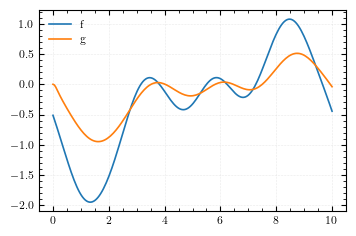

In [4]:
f_generator = fg.FunctionsGenerator(solver.t_array, l=1)

f = f_generator.generate_from_white_noise()

theta = solver.solve(f)
g = theta[solver.nx-1,:]

plt.plot(solver.t_array, f, label="f")
plt.plot(solver.t_array, g, label="g")
plt.legend()
plt.grid()
plt.minorticks_on()
plt.show()

In [5]:
def tikhonov_loss(f, g_target, lambda_reg : float):
    
    T = solver.solve(f)
    g_sim = T[-1, :]
    
    # Termine energetico differenza soluzione trovata e soluzione nota
    misfit = np.linalg.norm(g_sim - g_target)**2

    # Termine energetico sulla derivata
    reg = lambda_reg * np.linalg.norm(np.diff(f))**2

    return misfit + reg

In [6]:
from scipy.optimize import minimize

lambda_reg = 1e-3

g_target = g
f_guess = np.random.randn(nt) * 0.01

result = minimize(
    tikhonov_loss,
    f_guess,
    args=(g_target, lambda_reg),
    method='L-BFGS-B',
    options={'maxiter': 100}
)

f_reconstructed = result.x

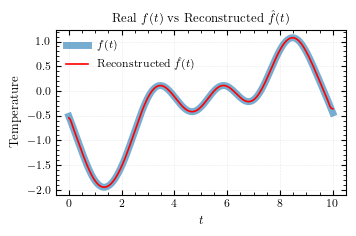

In [7]:
plt.figure()
plt.plot(solver.t_array, f, label=r"$f(t)$", lw=5, alpha=0.6)
plt.plot(solver.t_array, f_reconstructed, label=r"Reconstructed $\hat{f}(t)$", c="r")
plt.xlabel(r"$t$")
plt.ylabel("Temperature")
plt.title(r"Real $f(t)$ vs Reconstructed $\hat{f}(t)$")
plt.grid()
plt.legend()
plt.minorticks_on()
plt.savefig("assets/tikonov_reconstructed_function.pdf")
plt.show()

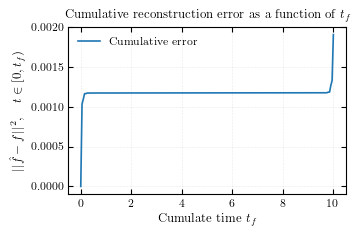

In [8]:
loss_array = np.zeros(nt)

for n in range(nt):
    loss_array[n] = np.linalg.norm(f[0:n] - f_reconstructed[0:n])**2

plt.figure()
plt.plot(solver.t_array, loss_array, label="Cumulative error")
plt.ylabel(r"$||\hat{f} - f||^2, \hspace{1em} t \in [0,t_f)$")
plt.xlabel(r"Cumulate time $t_f$")
plt.title(r"Cumulative reconstruction error as a function of $t_f$")
plt.legend()
plt.grid()
plt.show()